# Tutorial: from raw data to the LaTeX report

This notebook walks through a complete analysis and uses every function of pemlab once. It works
with two measurement series that lie in `tutorial_data/`:

1. `resistor.csv`: voltage and current at an ohmic resistor (a linear fit gives the resistance)
2. `lowpass.csv`: gain of an RC low-pass filter over frequency (a nonlinear fit gives the cutoff
   frequency)

The raw CSV files are never changed.

In [1]:
import pandas as pd

pd.read_csv("tutorial_data/resistor.csv").head(3)

,U [V],I [mA]
0,0.943,2.0
1,1.870,4.0
2,2.828,6.0


In [2]:
pd.read_csv("tutorial_data/lowpass.csv").head(3)

,f [Hz],U_in [V],U_out [V],sigma_U_out [V]
0,100,2.0,2.005,0.01
1,200,2.0,1.992,0.01
2,400,2.0,1.940,0.01


## 1. The project

A `Project` knows the build folder. You set it once, and at the end a single
`lab.build()` writes everything there. `tex_prefix` is the path with which LaTeX finds the build
folder from your report (here the report would lie next to this notebook).

In [3]:
from pemlab import NumberStyle, Project

lab = Project("pemlab_build", tex_prefix="pemlab_build")

## 2. Edit the resistor data

`edit_csv` loads the file for editing. A column name is a label, by convention with the unit in
square brackets. pemlab derives nothing from the names, so we write each name **once** as a
variable and reuse it everywhere. Names may contain math (`$\sigma_U$`) and `\Omega`.
Every editing method returns the table, so the notebook shows the current state after each step.

In [4]:
U = "U [V]"
I_mA = "I [mA]"
I = "I [A]"
SIGMA_U = r"$\sigma_U$ [V]"
R = r"$R$ [\Omega]"
SIGMA_R = r"$\sigma_R$ [\Omega]"

resistor = lab.edit_csv("tutorial_data/resistor.csv", name="resistor")
resistor.df.head(3)

,U [V],I [mA]
0,0.943,2.0
1,1.870,4.0
2,2.828,6.0


**`replace_column`** changes a column in place instead of adding a new one. The formula has the
variable `I_mA`, and the keyword argument `I_mA=I_mA` assigns the old column to it (the first is the
name in the formula, the second our variable with the column name). The new column is `I [A]`.
`show=False` keeps this trivial unit conversion out of the "Calculations" list in the report.

In [5]:
resistor.replace_column(I_mA, I, "I_mA * 1e-3", I_mA=I_mA, show=False)

,U [V],I [A]
0,0.943,0.002
1,1.870,0.004
2,2.828,0.006
3,3.769,0.008
4,4.680,0.010
5,5.627,0.012
6,6.581,0.014
7,7.517,0.016
8,8.460,0.018
9,9.391,0.020


**`add_uncertainty`** propagates uncertainties. The voltmeter has no uncertainty column in the
CSV, so we pass its accuracy as a constant. `sigmas` names the uncertainty of every variable of
the formula. The formula `"U"` simply turns this constant into a column.

In [6]:
resistor.add_uncertainty(SIGMA_U, "U", {"U": 0.01}, U=U)

,U [V],I [A],$\sigma_U$ [V]
0,0.943,0.002,0.01
1,1.870,0.004,0.01
2,2.828,0.006,0.01
3,3.769,0.008,0.01
4,4.680,0.010,0.01
5,5.627,0.012,0.01
6,6.581,0.014,0.01
7,7.517,0.016,0.01
8,8.460,0.018,0.01
9,9.391,0.020,0.01


**`add_column`** adds a column computed from a formula. `numbers=NumberStyle(decimals=1)` rounds
only the display in the table, the stored values keep all digits. Here every variable of the
formula is assigned a column explicitly; a variable that is the name of a column (`U` for
`U [V]`) does not need that. `show=True` lists the calculation in the report.

In [7]:
resistor.add_column(R, "U / I", U=U, I=I, numbers=NumberStyle(decimals=1), show=True)

,U [V],I [A],$\sigma_U$ [V],$R$ [\Omega]
0,0.943,0.002,0.01,471.5
1,1.870,0.004,0.01,467.5
2,2.828,0.006,0.01,471.3
3,3.769,0.008,0.01,471.1
4,4.680,0.010,0.01,468.0
5,5.627,0.012,0.01,468.9
6,6.581,0.014,0.01,470.1
7,7.517,0.016,0.01,469.8
8,8.460,0.018,0.01,470.0
9,9.391,0.020,0.01,469.6


Now the uncertainty of $R = U/I$. pemlab differentiates the formula analytically. In `sigmas`,
the uncertainty of `U` is the column we just created, the one of `I` is a constant.

In [8]:
resistor.add_uncertainty(
    SIGMA_R, "U / I", {"U": SIGMA_U, "I": 2e-5}, U=U, I=I,
    numbers=NumberStyle(decimals=1), show=True,
)

,U [V],I [A],$\sigma_U$ [V],$R$ [\Omega],$\sigma_R$ [\Omega]
0,0.943,0.002,0.01,471.5,6.9
1,1.870,0.004,0.01,467.5,3.4
2,2.828,0.006,0.01,471.3,2.3
3,3.769,0.008,0.01,471.1,1.7
4,4.680,0.010,0.01,468.0,1.4
5,5.627,0.012,0.01,468.9,1.1
6,6.581,0.014,0.01,470.1,1.0
7,7.517,0.016,0.01,469.8,0.9
8,8.460,0.018,0.01,470.0,0.8
9,9.391,0.020,0.01,469.6,0.7


Every calculation is recorded. This is what ends up in the report:

In [9]:
for calculation in resistor.calculations:
    print(f"{calculation.column:>22}  =  {calculation.formula}")

                 I [A]  =  I_mA * 1e-3
        $\sigma_U$ [V]  =  U
          $R$ [\Omega]  =  U / I
   $\sigma_R$ [\Omega]  =  U / I


## 3. Plot and fit

`lab.analysis` creates an analysis for a table. `make_PlotData` selects columns by their full name
(x, y and optionally the uncertainty of y).

In [10]:
analysis = lab.analysis(resistor)
data = analysis.make_PlotData(I, U, SIGMA_U)

`plot_data` plots only the measured points. The first argument is the name of the plot, it names
the folder and the files in the build folder.

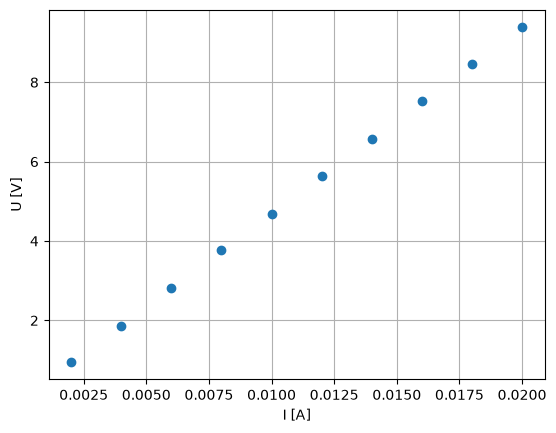

In [11]:
analysis.plot_data("resistor_data", data)

`regression` fits a function. The first argument of the function is `x`, the others are the fit
parameters, and the result is a single `return` line so that pemlab can show the formula. The
result gives the parameters with uncertainties and the chi-squared per degree of freedom.

R = 469.69 ± 0.25
chi²/ndf = 7.62/9 = 0.847


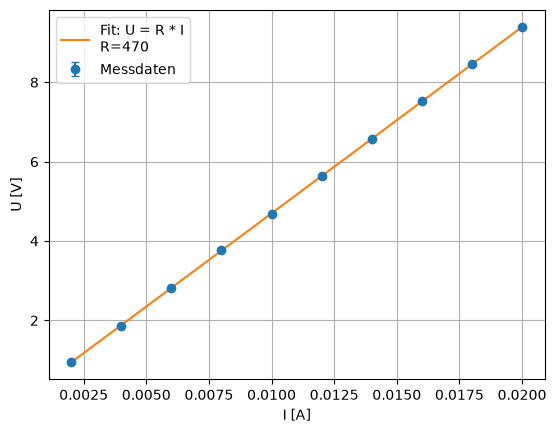

In [12]:
def ohm(x, R):
    return R * x


result = analysis.regression("ohms_law", ohm, data)

In [13]:
result

FitResult(R=470)

## 4. The mean of a series

`mean` gives the mean of a column with its standard deviation and the uncertainty of the mean
(standard error). `reference` adds the deviation from a known value, here 470 $\Omega$.

In [14]:
mean_result = analysis.mean("resistance_mean", R, reference=470)

n = 10
mean = 469.78 ± 0.43
standard deviation = 1.35
deviation from 470 = -0.22, -0.047 %, 0.52 sigma


With `sigma` (a column of uncertainties) the weighted mean is used. The reduced chi-squared
shows whether the values agree within their uncertainties.

In [15]:
weighted_result = analysis.mean("resistance_weighted", R, sigma=SIGMA_R, reference=470)

n = 10
weighted mean = 469.69 ± 0.36
standard deviation = 1.35
chi²/ndf = 0.443
deviation from 470 = -0.314, -0.067 %, 0.88 sigma


## 5. A nonlinear fit

The same steps for the low-pass. Columns without a unit are allowed, because the gain
$H = U_\mathrm{out}/U_\mathrm{in}$ is dimensionless. `lowpass.csv` already has a column with the
uncertainty of `U_out`, for `U_in` we pass a constant.

In [16]:
F = "f [Hz]"
U_IN = "U_in [V]"
U_OUT = "U_out [V]"
SIGMA_U_OUT = "sigma_U_out [V]"
H = "H"
SIGMA_H = r"$\sigma_H$"

lowpass = lab.edit_csv("tutorial_data/lowpass.csv", name="lowpass")
lowpass.add_column(
    H, "U_out / U_in", U_out=U_OUT, U_in=U_IN, numbers=NumberStyle(decimals=4), show=True
)
lowpass.add_uncertainty(
    SIGMA_H, "U_out / U_in", {"U_out": SIGMA_U_OUT, "U_in": 0.01},
    U_out=U_OUT, U_in=U_IN, numbers=NumberStyle(decimals=4), show=True,
)

,f [Hz],U_in [V],U_out [V],sigma_U_out [V],H,$\sigma_H$
0,100,2.0,2.005,0.01,1.0025,0.0071
1,200,2.0,1.992,0.01,0.9960,0.0071
2,400,2.0,1.940,0.01,0.9700,0.0070
3,700,2.0,1.842,0.01,0.9210,0.0068
4,1000,2.0,1.698,0.01,0.8490,0.0066
5,1500,2.0,1.447,0.01,0.7235,0.0062
6,2000,2.0,1.249,0.01,0.6245,0.0059
7,3000,2.0,0.928,0.01,0.4640,0.0055
8,5000,2.0,0.615,0.01,0.3075,0.0052
9,8000,2.0,0.390,0.01,0.1950,0.0051


For nonlinear functions, start values `p0` help the fit.

f_g = 1591 ± 12
chi²/ndf = 3.45/10 = 0.345


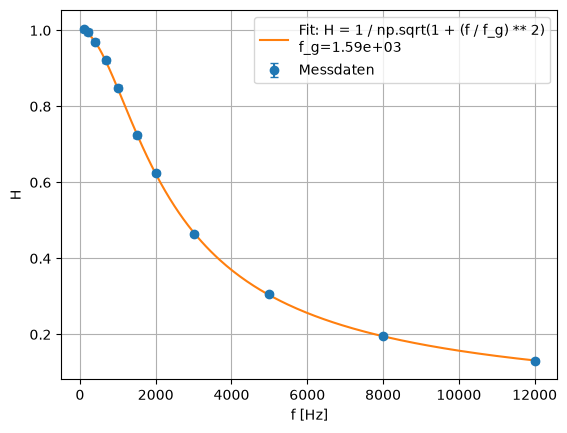

In [17]:
import numpy as np


def lowpass_model(x, f_g):
    return 1 / np.sqrt(1 + (x / f_g) ** 2)


lowpass_analysis = lab.analysis(lowpass)
lowpass_data = lowpass_analysis.make_PlotData(F, H, SIGMA_H)
lowpass_result = lowpass_analysis.regression("lowpass_gain", lowpass_model, lowpass_data, p0=[1500])

## 6. Tables of the raw data and build

`tables_from_folder` creates a LaTeX table for every CSV file in a folder. Then `build` writes
everything. It first deletes the build folder, so no stale files remain.

In [18]:
lab.tables_from_folder("tutorial_data")
lab.build()

## 7. What was written

One folder per table and per plot, and the files have the name you gave:

In [19]:
from pathlib import Path

build = Path("pemlab_build")
for path in sorted(build.rglob("*")):
    if path.is_file():
        print(path.relative_to(build).as_posix())

.pemlab-build
data/lowpass/lowpass.calc.json
data/lowpass/lowpass.csv
data/lowpass/lowpass.tex
data/resistor/resistor.calc.json
data/resistor/resistor.csv
data/resistor/resistor.tex
means/resistance_mean/resistance_mean.tex
means/resistance_weighted/resistance_weighted.tex
plots/lowpass_gain/lowpass_gain.pdf
plots/lowpass_gain/lowpass_gain.png
plots/lowpass_gain/lowpass_gain.tex
plots/ohms_law/ohms_law.pdf
plots/ohms_law/ohms_law.png
plots/ohms_law/ohms_law.tex
plots/resistor_data/resistor_data.pdf
plots/resistor_data/resistor_data.png
plots/resistor_data/resistor_data.tex
tables/lowpass/lowpass.tex
tables/resistor/resistor.tex


The plot comes as a single LaTeX float: figure, caption, fit result and the calculations that
were used.

In [20]:
print((build / "plots" / "ohms_law" / "ohms_law.tex").read_text(encoding="utf-8"))

\begin{figure}[H]
  \centering
  \includegraphics[width=0.8\textwidth]{pemlab_build/plots/ohms_law/ohms_law.pdf}
  \caption{U [V] vs. I [A]}
  \label{fig:ohms_law}
  \par\medskip
  {\footnotesize
Regression: $U = I \cdot R$
\par\smallskip
\begin{tabular}{lrr}
  parameter & value & error \\
  \hline
  $R$ & $469.69$ & $\pm 0.25$ \\
\end{tabular}
\par\smallskip
$\chi^2/\mathrm{ndf} = 7.62/9 = 0.847$
  \par\smallskip
Calculations:
$\sigma_U = \sigma_{U}$ (with $\sigma_{U} = \SI{0.01}{V}$)
  }
\end{figure}



The edited table carries its calculations in the same way:

In [21]:
print((build / "data" / "resistor" / "resistor.tex").read_text(encoding="utf-8"))

\begin{table}[H]
  \centering
  \begin{tabular}{@{}ccccc@{}}
    \toprule
    U [V] & I [A] & $\sigma_U$ [V] & $R$ [$\Omega$] & $\sigma_R$ [$\Omega$] \\
    \midrule
    0.943 & 0.002 & 0.01 & 471.5 & 6.9 \\
    1.87 & 0.004 & 0.01 & 467.5 & 3.4 \\
    2.828 & 0.006 & 0.01 & 471.3 & 2.3 \\
    3.769 & 0.008 & 0.01 & 471.1 & 1.7 \\
    4.68 & 0.01 & 0.01 & 468 & 1.4 \\
    5.627 & 0.012 & 0.01 & 468.9 & 1.1 \\
    6.581 & 0.014 & 0.01 & 470.1 & 1 \\
    7.517 & 0.016 & 0.01 & 469.8 & 0.9 \\
    8.46 & 0.018 & 0.01 & 470 & 0.8 \\
    9.391 & 0.02 & 0.01 & 469.6 & 0.7 \\
    \bottomrule
  \end{tabular}
  \caption{resistor}
  \label{tab:resistor}
  \par\medskip
  {\footnotesize
Calculations:
$\sigma_U = \sigma_{U}$ (with $\sigma_{U} = \SI{0.01}{V}$)
\qquad
$R = \frac{U}{I}$
\qquad
$\sigma_R = \sqrt{\frac{\sigma_{U}^{2}}{I^{2}} + \frac{U^{2} \cdot \sigma_{I}^{2}}{I^{4}}}$ (with $\sigma_{I} = \SI{2e-05}{A}$)
  }
\end{table}



## 8. Include it in your report

The report needs `graphicx`, `booktabs`, `siunitx` and `float`. Then include what you want, where
you want it:

```latex
\documentclass{article}
\usepackage{graphicx}
\usepackage{booktabs}
\usepackage{siunitx}
\usepackage{float}

\begin{document}

\input{pemlab_build/data/resistor/resistor}
\input{pemlab_build/plots/ohms_law/ohms_law}
\input{pemlab_build/means/resistance_mean/resistance_mean}
\input{pemlab_build/plots/lowpass_gain/lowpass_gain}

\end{document}
```